# Phase 2c: Family-level damage model + exact solver for in-between sizes

**What the Phase 3 run showed.**
- Experiment A: the embedding at q4_k costs **+3.70%** perplexity (q5_k +0.76%, q6_k +0.16%). That explains the Phase 2b failure.
- Experiment B: damages of whole tensor families are **additive** (joint damage only 2-4% above the sum of the parts). Single tensors were too small to measure, but whole families are not.
- The hill-climb from the imatrix Q4_K_M reached **+0.27%** better test perplexity at equal size (guided) and **+0.002%** (random), at a cost of 3.3 GPU hours, with 31% of the guided evaluations wasted on repeated moves.

**Plan of this notebook.** The presets exist only at a few sizes (about 676 / 824 / 986 / 1125 MB). Nothing is tuned in between. So:
1. **Rebuild and re-measure the Phase 3 results** on the **full** test split (the earlier numbers used 100 of about 645 chunks). The session reset deleted the models, so they are rebuilt from the logged move lists.
2. **Measure the damage of every tensor family** (22 families: kind x first/middle/last blocks, plus the embedding) at q3_k and q4_k, and at q5_k/q6_k for three large families to calibrate how damage shrinks with more bits.
3. **Fit a damage model** (one scale per family) and **solve exactly** (dynamic programming, no SciPy needed) for budgets of 824, 870, 920 and 986 MB. 824 and 986 equal the Q3_K_M and Q4_K_M sizes, so they are head-to-head comparisons; 870 and 920 fall in the gap where no preset exists.
4. **Verify with real runs** on the test split, against (a) the imatrix presets (a smooth curve through 4 of them), (b) random allocations of the same size, (c) the Phase 3 search results.
5. **Check the model itself:** predicted vs measured damage, the same plot that failed in Phase 2b.

**Honest expectations.** Allocation is uniform per family (one level per family), which cannot copy the preset's internal alternating pattern. A tie with the preset curve at the preset sizes plus a gain in between would already be a useful result, and no gain is possible too. All outcomes are reported with the same numbers.

**Protect your results.** After each stage a cell prints all measurements as text. Use **File -> Download Notebook** after each stage: the printed data travels with the notebook file (this is how the Phase 3 results survived the session reset). Run interactively, not with Save & Run All.

**Time (rough estimate, not measured):** setup 30 min; Stage A (presets and replays) about 60-80 min because of the full test runs; probes about 45-60 min; verification about 50-70 min.

In [5]:
import os, json, re, time, subprocess, pathlib, shutil, random, math
import numpy as np

os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # measure on ONE GPU even if Kaggle gives T4 x2

MODEL_ID    = "Qwen/Qwen2.5-1.5B"
MODEL_NAME  = MODEL_ID.split("/")[-1]
PIN         = "6b9ba4f"       # llama.cpp commit used in Phase 3, so the old numbers can be reproduced

LEVELS      = ["q3_k", "q4_k", "q5_k", "q6_k", "q8_0"]   # allowed per-tensor types, low -> high bits
HIGH        = LEVELS[-1]
N_EDGE      = 2               # first/last N blocks are the "edge" families
IMX_CHUNKS  = 200
SEARCH_CHUNKS = 80            # chunks of the SEARCH text (train slice) used for probes
TEST_CHUNKS = None            # None = the full test split (about 645 chunks)

PROBE_LEVELS = ["q3_k", "q4_k"]                         # every family is probed at these
CAL_FAMS     = ["token_embd:all", "ffn_down:mid", "ffn_up:mid"]   # large families also probed at CAL_LEVELS
CAL_LEVELS   = ["q5_k", "q6_k"]
BUDGETS_MB   = [824, 870, 920, 986]      # 824 / 986 equal the Q3_K_M / Q4_K_M preset sizes
RANDOM_BUDGETS, RANDOM_PER_BUDGET = [870, 920], 2
PRESETS      = ["Q2_K", "Q3_K_M", "Q4_K_M", "Q5_K_M"]  # the preset curve to beat

BENCH       = True            # GPU tokens/s for presets and DP configs
RUN_HELLASWAG = False         # perplexity differences of 0.3% are invisible to HellaSwag (+-2.4 points)
HS_TASKS    = 400
SAVE_FINAL_GGUFS = True       # write presets and in-between DP configs into results/final_models
SAVE_BUDGETS = [870, 920]
CLEANUP     = True

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))
for host in ["github.com", "huggingface.co", "pypi.org"]:
    r = subprocess.run(["curl", "-sS", "-o", "/dev/null", "-m", "10", "-w", "%{http_code}", f"https://{host}"],
                       capture_output=True, text=True)
    print(host, "->", r.stdout or r.stderr.strip())

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5
github.com -> 200
huggingface.co -> 200
pypi.org -> 200


## 1. Build llama.cpp at the Phase 3 commit
A full clone is needed to check out an old commit (takes a minute or two). If pinning fails, the notebook continues with the latest version and says so; small numeric differences from the Phase 3 run are then expected.

In [6]:
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone https://github.com/ggml-org/llama.cpp {LLAMA}")
        r = subprocess.run(f"git -C {LLAMA} checkout {PIN}", shell=True, text=True, capture_output=True)
        print("pinned to", PIN if r.returncode == 0 else f"FAILED ({r.stderr.strip()[:150]}), using the latest commit instead")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"
    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-perplexity llama-imatrix llama-bench")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT, "| matches Phase 3:", LLAMA_COMMIT.startswith(PIN[:6]))
print("per-tensor override flag available:", "--tensor-type" in sh(f"{BIN/'llama-quantize'} --help", check=False))

$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: 6b9ba4f2e | matches Phase 3: True
$ /kaggle/working/llama.cpp/build/bin/llama-quantize --help
per-tensor override flag available: True


## 2. Model, F16 GGUF and text slices
`--no-deps` keeps pip from touching numpy (last time a mid-session numpy change broke SciPy).
- **imatrix text:** first 3M characters of the WikiText-2 *train* split
- **search text:** a different 300k-character slice of *train* (used for accept/reject decisions)
- **test text:** the *test* split (only for reported numbers)

In [7]:
sh(f"pip install -q --no-deps {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID, local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"])
N_BLOCKS = json.load(open(pathlib.Path(hf_dir) / "config.json"))["num_hidden_layers"]
print("transformer blocks:", N_BLOCKS)

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

def get_text(split):
    try:
        from datasets import load_dataset
        return "".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)["text"])
    except Exception as e:
        print("datasets route failed, using parquet:", repr(e)[:150])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", f"wikitext-2-raw-v1/{split}-00000-of-00001.parquet",
                            repo_type="dataset")
        return "".join(pd.read_parquet(p)["text"])

WIKI, IMX_TEXT, SEARCH_TEXT = WORK / "wiki.test.raw", WORK / "imx.train.txt", WORK / "search.train.txt"
if not WIKI.exists():
    WIKI.write_text(get_text("test"))
if not IMX_TEXT.exists() or not SEARCH_TEXT.exists():
    train = get_text("train")
    assert len(train) > 5_400_000, "train split shorter than expected"
    IMX_TEXT.write_text(train[:3_000_000])
    SEARCH_TEXT.write_text(train[5_000_000:5_300_000])
print({p.name: f"{p.stat().st_size/1e6:.2f} MB" for p in (WIKI, IMX_TEXT, SEARCH_TEXT)})

$ pip install -q --no-deps /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

transformer blocks: 28
Qwen2.5-1.5B-F16.gguf 3094 MB
{'wiki.test.raw': '1.29 MB', 'imx.train.txt': '3.01 MB', 'search.train.txt': '0.30 MB'}


## 3. Importance matrix (saved to `results/` for reuse)

In [8]:
IMATRIX = MODELS / f"{MODEL_NAME}.imatrix"
IMATRIX_SAVED = RESULTS / f"{MODEL_NAME}.imatrix"
if IMATRIX_SAVED.exists() and not IMATRIX.exists():
    shutil.copy(IMATRIX_SAVED, IMATRIX)
if not IMATRIX.exists():
    t = time.time()
    sh(f"{BIN/'llama-imatrix'} -m {F16} -f {IMX_TEXT} -o {IMATRIX} -ngl 99 -c 512 --chunks {IMX_CHUNKS}")
    shutil.copy(IMATRIX, IMATRIX_SAVED)
    print(f"imatrix done in {time.time()-t:.0f}s")
print("imatrix:", IMATRIX.name, f"{IMATRIX.stat().st_size/1e6:.1f} MB")

imatrix: Qwen2.5-1.5B.imatrix 4.1 MB


## 4. Helpers
`eval_file` evaluates one GGUF on several texts at once, so a single (slow) quantization serves all measurements of a configuration.

In [9]:
BPW = {"q3_k": 3.4375, "q4_k": 4.5, "q5_k": 5.5, "q6_k": 6.5625, "q8_0": 8.5}
BPW_ALL = {**BPW, "q2_k": 2.625, "q4_0": 4.5, "q5_0": 5.5, "q4_1": 5.0, "q5_1": 6.0, "f16": 16.0, "bf16": 16.0, "f32": 32.0}

def exact_regex(names):
    return "^(" + "|".join(re.escape(n) for n in names) + ")$"

def run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError("failed: " + " ".join(map(str, cmd))[:300])
    return r.stdout, r.stderr

QUANT, PPLBIN, BENCHBIN = (str(BIN / n) for n in ("llama-quantize", "llama-perplexity", "llama-bench"))

def quantize(out, base, overrides=(), imatrix=True):
    cmd = [QUANT, "--imatrix", str(IMATRIX)] if imatrix else [QUANT]
    for pattern, qtype in overrides:
        cmd += ["--tensor-type", f"{pattern}={qtype}"]
    cmd += [str(F16), str(out), base]
    run(cmd)

def perplexity(path, text, chunks):
    cmd = [PPLBIN, "-m", str(path), "-f", str(text), "-ngl", "99", "-c", "512"]
    if chunks:
        cmd += ["--chunks", str(chunks)]
    so, se = run(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", so + se)
    if not m:
        raise RuntimeError((so + se)[-2000:])
    return float(m.group(1)), float(m.group(2))

def bench(path):
    so, se = run([BENCHBIN, "-m", str(path), "-p", "512", "-n", "128", "-r", "3", "-ngl", "99", "-o", "json"])
    rows = json.loads(so[so.index("["):])
    pp = next(r for r in rows if r["n_prompt"] > 0 and r["n_gen"] == 0)
    tg = next(r for r in rows if r["n_gen"] > 0 and r["n_prompt"] == 0)
    return pp["avg_ts"], tg["avg_ts"]

HS_FILE = WORK / "hellaswag_val_full.txt"
HS_OK = [RUN_HELLASWAG]
def hellaswag(path):
    if not HS_OK[0]:
        return None
    try:
        if not HS_FILE.exists():
            import urllib.request
            urllib.request.urlretrieve("https://raw.githubusercontent.com/klosax/hellaswag_text_data/main/hellaswag_val_full.txt", HS_FILE)
        so, se = run([PPLBIN, "-m", str(path), "-f", str(HS_FILE), "--hellaswag",
                      "--hellaswag-tasks", str(HS_TASKS), "-ngl", "99"])
        rows = re.findall(r"^\s*(\d+)\s+([\d.]+)%", so + se, re.M)
        return float(rows[-1][1]) if rows else None
    except Exception as e:
        print("hellaswag skipped:", repr(e)[:200])
        HS_OK[0] = False
        return None

def tensor_types(path):
    from gguf import GGUFReader
    return {t.name: t.tensor_type.name for t in GGUFReader(str(path)).tensors}

# groups = every 2-D weight matrix of the model (norms and biases are 1-D and stay F32)
from gguf import GGUFReader
GROUPS = [{"id": t.name, "n": int(t.n_elements)} for t in GGUFReader(str(F16)).tensors if len(t.shape) == 2]
_pat = re.compile(r"blk\.(\d+)\.(\w+)\.weight")
for g in GROUPS:
    m = _pat.fullmatch(g["id"])
    g["block"] = int(m.group(1)) if m else -1
    g["kind"] = m.group(2) if m else g["id"].replace(".weight", "")
N_ELEM = np.array([g["n"] for g in GROUPS], dtype=float)
G = len(GROUPS)
HI = len(LEVELS) - 1
print(f"{G} weight tensors, {N_ELEM.sum()/1e6:.0f}M weights")

FIXED_BYTES = None            # set by the self-test
BPW_VEC = np.array([BPW[l] for l in LEVELS])
def size_mb(idx):
    return (FIXED_BYTES + (N_ELEM * BPW_VEC[idx] / 8.0).sum()) / 1e6

def overrides_from_idx(idx):
    by_level = {}
    for g, l in zip(GROUPS, idx):
        if LEVELS[l] != HIGH:
            by_level.setdefault(LEVELS[l], []).append(g["id"])
    return [(exact_regex(names), lvl) for lvl, names in by_level.items()]

RESULTS_FILE = RESULTS / f"phase2c_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["name"]] = r

def log(name, rec, **meta):
    rec = {"name": name, **rec, **meta}
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    return rec

SPEC_SEARCH = {"search": (SEARCH_TEXT, SEARCH_CHUNKS)}
SPEC_HEAD   = {"search": (SEARCH_TEXT, SEARCH_CHUNKS), "full": (WIKI, TEST_CHUNKS)}

def eval_file(path, specs, do_bench=False, do_hs=False):
    rec = {"size_mb": path.stat().st_size / 1e6}
    for key, (text, chunks) in specs.items():
        rec[f"ppl_{key}"], rec[f"err_{key}"] = perplexity(path, text, chunks)
    if do_bench and BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(path)
    if do_hs:
        rec["hellaswag"] = hellaswag(path)
    return rec

def short(rec):
    ppls = "  ".join(f"ppl[{k[4:]}]={rec[k]:.4f}" for k in rec if k.startswith("ppl_"))
    return ppls + f"  size={rec['size_mb']:.1f} MB  {rec['secs']:.0f}s"

def evaluate_multi(name, idx, specs, do_bench=False, do_hs=False, **meta):
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, HIGH, overrides_from_idx(idx))
    rec = eval_file(out, specs, do_bench, do_hs)
    out.unlink()
    rec["secs"] = time.time() - t
    print(f"{name[:38]:38s} {short(rec)}")
    return log(name, rec, levels=[LEVELS[int(i)] for i in idx], **meta)

def idx_of(rec):
    return np.array([LEVELS.index(l) for l in rec["levels"]])

def dump(prefixes):
    # print records as compact JSON lines: they stay inside the notebook file when you download it
    for name, r in records.items():
        if any(name.startswith(p) for p in prefixes):
            print(json.dumps({k: (round(v, 5) if isinstance(v, float) else v)
                              for k, v in r.items() if k not in ("levels", "types", "move")}))

197 weight tensors, 1544M weights


## 5. Self-test (run before anything long)
Per-tensor overrides must apply, and the size model must match real file sizes. The numbers feed the search's feasibility check, so a failure here must be fixed first.

In [10]:
plain = MODELS / "selftest_plain.gguf"; mixed = MODELS / "selftest_mixed.gguf"
quantize(plain, HIGH, [], imatrix=False)
FIXED_BYTES = plain.stat().st_size - (N_ELEM * BPW[HIGH] / 8.0).sum()      # norms, biases, metadata
print(f"fixed (non-group) bytes: {FIXED_BYTES/1e6:.1f} MB")

a, b = GROUPS[0], GROUPS[-1] if GROUPS[-1]["id"] != GROUPS[0]["id"] else GROUPS[1]
quantize(mixed, HIGH, [(exact_regex([a["id"]]), "q3_k"), (exact_regex([b["id"]]), "q5_k")], imatrix=False)
tt = tensor_types(mixed)
print(a["id"], "->", tt[a["id"]], "|", b["id"], "->", tt[b["id"]])
others = {v for k, v in tt.items() if k not in (a["id"], b["id"]) and "norm" not in k and not k.endswith(".bias")}
print("all other weight tensors:", others)
idx_t = np.full(G, len(LEVELS) - 1)
idx_t[0 if a is GROUPS[0] else 1] = LEVELS.index("q3_k")
idx_t[G - 1 if b is GROUPS[-1] else 1] = LEVELS.index("q5_k")
pred, act = size_mb(idx_t), mixed.stat().st_size / 1e6
print(f"size model: predicted {pred:.1f} MB, actual {act:.1f} MB, error {100*(pred/act-1):+.2f}%")
plain.unlink(); mixed.unlink()
assert tt[a["id"]] == "Q3_K" and tt[b["id"]] == "Q5_K" and others == {"Q8_0"}, "overrides not applied as expected: paste this output"
assert abs(pred / act - 1) < 0.02, "size model off by more than 2%: paste this output"
print("OK: overrides and size model work")

fixed (non-group) bytes: 6.5 MB
token_embd.weight -> Q3_K | blk.9.attn_v.weight -> Q5_K
all other weight tensors: {'Q8_0'}
size model: predicted 1498.7 MB, actual 1498.7 MB, error +0.00%
OK: overrides and size model work


## 5b. Family definitions and the exact solver
Families are the same as in Phase 3 (kind x first 2 / middle / last 2 blocks, plus the embedding), so the Phase 3 move lists can be replayed. The solver is a dynamic program, tested here against brute force.

In [11]:
# ---- families: (tensor kind) x (position bucket) --------------------------------
def bucket_of(g):
    if g["block"] < 0:
        return "all"
    if g["block"] < N_EDGE:
        return "lo"
    if g["block"] >= N_BLOCKS - N_EDGE:
        return "hi"
    return "mid"

for g in GROUPS:
    g["fam"] = f"{g['kind']}:{bucket_of(g)}"
FAMS = sorted({g["fam"] for g in GROUPS})
FAM_GROUPS = {f: np.array([i for i, g in enumerate(GROUPS) if g["fam"] == f]) for f in FAMS}


FAM_N = {f: float(N_ELEM[FAM_GROUPS[f]].sum()) for f in FAMS}
def apply_move(idx, move):
    new = idx.copy()
    for fam, d in move:
        sel = FAM_GROUPS[fam]
        new[sel] = np.clip(new[sel] + d, 0, len(LEVELS) - 1)
    return new


print(len(FAMS), 'families:', FAMS)

22 families: ['attn_k:hi', 'attn_k:lo', 'attn_k:mid', 'attn_output:hi', 'attn_output:lo', 'attn_output:mid', 'attn_q:hi', 'attn_q:lo', 'attn_q:mid', 'attn_v:hi', 'attn_v:lo', 'attn_v:mid', 'ffn_down:hi', 'ffn_down:lo', 'ffn_down:mid', 'ffn_gate:hi', 'ffn_gate:lo', 'ffn_gate:mid', 'ffn_up:hi', 'ffn_up:lo', 'ffn_up:mid', 'token_embd:all']


In [12]:
def solve_dp(D, S, cap, unit=20_000.0):
    # Exact multiple-choice knapsack by dynamic programming: one level per family,
    # total bytes <= cap, minimise total predicted damage. Sizes are rounded UP to 'unit'
    # bytes, so the result never exceeds the cap (it can waste at most F*unit bytes).
    F, L = D.shape
    W = np.ceil(S / unit).astype(int)
    U = int(cap // unit)
    INF = 1e18
    dp = np.zeros(U + 1)                         # best damage using the families so far with total <= s
    choice = np.zeros((F, U + 1), dtype=np.int8)
    for f in range(F):
        new = np.full(U + 1, INF)
        ch = np.zeros(U + 1, dtype=np.int8)
        for l in range(L):
            w = int(W[f, l])
            if w > U:
                continue
            cand = np.full(U + 1, INF)
            cand[w:] = dp[:U + 1 - w] + D[f, l]
            better = cand < new
            new[better] = cand[better]
            ch[better] = l
        dp, choice[f] = new, ch
    if dp[U] >= INF / 2:
        raise ValueError("budget is smaller than the cheapest possible allocation")
    idx = np.zeros(F, dtype=int)
    s = U
    for f in range(F - 1, -1, -1):
        idx[f] = choice[f, s]
        s -= int(W[f, idx[f]])
    return idx, float(dp[U])

def random_alloc(S, cap, rng, tol=0.985, tries=200_000):
    # a random level per family whose size lands within [tol*cap, cap]: the "no model" control
    F, L = S.shape
    for _ in range(tries):
        idx = np.array([rng.randrange(L) for _ in range(F)])
        s = S[np.arange(F), idx].sum()
        if tol * cap <= s <= cap:
            return idx
    raise RuntimeError("could not draw a random allocation inside the size window")

# unit test: DP must match brute force on a small random instance
rng_t = np.random.default_rng(3)
F_t, L_t = 6, len(LEVELS)
N_t = rng_t.integers(1_000_000, 30_000_000, F_t).astype(float)
S_t = np.array([[n * BPW[l] / 8.0 for l in LEVELS] for n in N_t])
D_t = rng_t.lognormal(-5, 1, F_t)[:, None] * np.array([1.0, 0.25, 0.06, 0.015, 0.0])[None, :]
cap_t = 0.55 * S_t[:, -1].sum() + 0.45 * S_t[:, 0].sum()
import itertools
best = min((D_t[np.arange(F_t), c].sum(), c) for c in itertools.product(range(L_t), repeat=F_t)
           if S_t[np.arange(F_t), c].sum() <= cap_t)
idx_t, dmg_t = solve_dp(D_t, S_t, cap_t, unit=1_000.0)
print(f"brute force {best[0]:.6f} | DP {dmg_t:.6f} | DP size ok: {S_t[np.arange(F_t), idx_t].sum() <= cap_t}")
assert S_t[np.arange(F_t), idx_t].sum() <= cap_t and dmg_t <= best[0] * 1.02, "DP is not near-optimal: paste this output"
print("OK: solver works")

brute force 0.000443 | DP 0.000443 | DP size ok: True
OK: solver works


## 6. Stage A: baselines and replay of the Phase 3 results (full test split)
- The four imatrix presets give the curve to beat. Each is evaluated once on the search text (80 chunks) and on the **full** test split.
- The Phase 3 guided and random results are rebuilt from the logged accepted moves, starting from the Q4_K_M preset. Sizes and search perplexity are checked against the logged values (984.78 / 985.88 MB; 8.8646 / 8.8826 search ppl; the preset had 8.9310).

In [13]:
def nearest_level(tname):
    b = BPW_ALL.get(tname.lower(), 8.5)
    return min(range(len(LEVELS)), key=lambda i: abs(BPW[LEVELS[i]] - b))

def preset_record(q):
    name = f"preset_imx_{q}"
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, q, [], imatrix=True)
    tt = tensor_types(out)
    idx = [nearest_level(tt[g["id"]]) for g in GROUPS]
    unmapped = sum(1 for g in GROUPS if tt[g["id"]].lower() not in BPW)
    rec = eval_file(out, SPEC_HEAD, do_bench=True)
    out.unlink()
    rec["secs"] = time.time() - t
    print(f"{name:38s} {short(rec)}  unmapped tensors={unmapped}")
    return log(name, rec, levels=[LEVELS[i] for i in idx], types=[tt[g["id"]] for g in GROUPS], unmapped=unmapped)

for q in PRESETS:
    preset_record(q)

OLD_GUIDED = [(("attn_v:mid", 1), ("ffn_gate:lo", -1)), (("attn_output:lo", 1),), (("ffn_up:hi", 1), ("ffn_down:hi", -1)),
              (("attn_output:hi", 1),), (("ffn_up:lo", 1), ("ffn_down:lo", -1))]
OLD_RANDOM = [(("ffn_up:lo", 1), ("ffn_gate:lo", -1)), (("attn_k:mid", 1), ("ffn_up:lo", -1)),
              (("attn_output:lo", 1), ("attn_v:lo", -1)), (("attn_v:hi", 1), ("attn_k:mid", -1)),
              (("ffn_up:hi", 1), ("attn_q:hi", -1))]
OLD_LOG = {"old_guided": (984.7826, 8.8646), "old_random": (985.8823, 8.8826)}   # size MB, search ppl in Phase 3

seed_idx = idx_of(records["preset_imx_Q4_K_M"])
print("Phase 3 search ppl of the Q4_K_M preset was 8.9310; now:", round(records["preset_imx_Q4_K_M"]["ppl_search"], 4))
for name, moves in [("old_guided", OLD_GUIDED), ("old_random", OLD_RANDOM)]:
    cfg = seed_idx.copy()
    for mv in moves:
        cfg = apply_move(cfg, mv)
    logged_size, logged_ppl = OLD_LOG[name]
    print(f"{name}: rebuilt size {size_mb(cfg):.2f} MB (Phase 3: {logged_size:.2f})")
    assert abs(size_mb(cfg) - logged_size) < 0.3, "rebuilt config does not match the Phase 3 size: paste this output"
    rec = evaluate_multi(name, cfg, SPEC_HEAD, do_bench=True, group="old")
    print(f"   search ppl {rec['ppl_search']:.4f} (Phase 3: {logged_ppl:.4f}) -> "
          f"{'reproduced' if abs(rec['ppl_search'] - logged_ppl) < 0.003 else 'differs, check the llama.cpp commit above'}")

preset_imx_Q2_K                        ppl[search]=11.5781  ppl[full]=13.0314  size=676.3 MB  308s  unmapped tensors=112
preset_imx_Q3_K_M                      ppl[search]=9.4146  ppl[full]=10.5856  size=824.2 MB  259s  unmapped tensors=0
preset_imx_Q4_K_M                      ppl[search]=8.9310  ppl[full]=9.9229  size=986.0 MB  295s  unmapped tensors=0
preset_imx_Q5_K_M                      ppl[search]=8.6987  ppl[full]=9.7403  size=1125.1 MB  297s  unmapped tensors=0
Phase 3 search ppl of the Q4_K_M preset was 8.9310; now: 8.931
old_guided: rebuilt size 984.78 MB (Phase 3: 984.78)
old_guided                             ppl[search]=8.8646  ppl[full]=9.8887  size=984.8 MB  287s
   search ppl 8.8646 (Phase 3: 8.8646) -> reproduced
old_random: rebuilt size 985.88 MB (Phase 3: 985.88)
old_random                             ppl[search]=8.8826  ppl[full]=9.9074  size=985.9 MB  283s
   search ppl 8.8826 (Phase 3: 8.8826) -> reproduced


In [14]:
# results of Stage A as printed text (survives in the downloaded notebook)
dump(["preset_imx_", "old_"])

{"name": "preset_imx_Q2_K", "size_mb": 676.30461, "ppl_search": 11.5781, "err_search": 0.21706, "ppl_full": 13.0314, "err_full": 0.0931, "pp_tps": 3368.60241, "tg_tps": 141.55728, "secs": 307.60198, "unmapped": 112}
{"name": "preset_imx_Q3_K_M", "size_mb": 824.1784, "ppl_search": 9.4146, "err_search": 0.1771, "ppl_full": 10.5856, "err_full": 0.07514, "pp_tps": 4157.99655, "tg_tps": 127.25039, "secs": 258.62473, "unmapped": 0}
{"name": "preset_imx_Q4_K_M", "size_mb": 986.04822, "ppl_search": 8.931, "err_search": 0.16741, "ppl_full": 9.9229, "err_full": 0.0697, "pp_tps": 4486.4128, "tg_tps": 126.85503, "secs": 294.68535, "unmapped": 0}
{"name": "preset_imx_Q5_K_M", "size_mb": 1125.05008, "ppl_search": 8.6987, "err_search": 0.16094, "ppl_full": 9.7403, "err_full": 0.06802, "pp_tps": 4355.34268, "tg_tps": 119.05799, "secs": 297.25603, "unmapped": 0}
{"name": "old_guided", "size_mb": 984.78256, "ppl_search": 8.8646, "err_search": 0.16504, "ppl_full": 9.8887, "err_full": 0.06926, "pp_tps": 4

## 7. Stage B: damage of every tensor family
Each family is set to q3_k and to q4_k with everything else at q8_0 (all tensors of the family at once, so the effect is large enough to measure). The three biggest families are also probed at q5_k and q6_k to calibrate how fast damage shrinks with more bits. About 50 evaluations.

In [15]:
ref = evaluate_multi("ref_q8", np.full(G, HI), SPEC_SEARCH, group="ref")
ref_s = ref["ppl_search"]
print("reference (all q8_0) search ppl:", round(ref_s, 4))

def family_cfg(fam, lvl):
    cfg = np.full(G, HI)
    cfg[FAM_GROUPS[fam]] = LEVELS.index(lvl)
    return cfg

t0 = time.time()
for f in sorted(FAMS, key=lambda f: -FAM_N[f]):
    for l in PROBE_LEVELS:
        evaluate_multi(f"probe_{f}_{l}", family_cfg(f, l), SPEC_SEARCH, group="probe", fam=f, level=l)
for f in CAL_FAMS:
    for l in CAL_LEVELS:
        evaluate_multi(f"probe_{f}_{l}", family_cfg(f, l), SPEC_SEARCH, group="probe", fam=f, level=l)
print(f"probing took {(time.time()-t0)/60:.0f} min in this run (0 if everything was cached)")

ref_q8                                 ppl[search]=8.6451  size=1646.6 MB  34s
reference (all q8_0) search ppl: 8.6451
probe_ffn_down:mid_q3_k                ppl[search]=8.8222  size=1437.6 MB  41s
probe_ffn_down:mid_q4_k                ppl[search]=8.7028  size=1481.4 MB  63s
probe_ffn_gate:mid_q3_k                ppl[search]=8.7544  size=1437.6 MB  41s
probe_ffn_gate:mid_q4_k                ppl[search]=8.6772  size=1481.4 MB  63s
probe_ffn_up:mid_q3_k                  ppl[search]=8.8826  size=1437.6 MB  41s
probe_ffn_up:mid_q4_k                  ppl[search]=8.7133  size=1481.4 MB  63s
probe_token_embd:all_q3_k              ppl[search]=9.9997  size=1498.9 MB  35s
probe_token_embd:all_q4_k              ppl[search]=8.9648  size=1529.9 MB  45s
probe_attn_output:mid_q3_k             ppl[search]=8.7535  size=1610.7 MB  35s
probe_attn_output:mid_q4_k             ppl[search]=8.6577  size=1618.3 MB  39s
probe_attn_q:mid_q3_k                  ppl[search]=8.6849  size=1610.7 MB  36s
probe_attn_q

In [16]:
dump(["ref_q8", "probe_"])

{"name": "ref_q8", "size_mb": 1646.57277, "ppl_search": 8.6451, "err_search": 0.15982, "secs": 33.90051, "group": "ref"}
{"name": "probe_ffn_down:mid_q3_k", "size_mb": 1437.55389, "ppl_search": 8.8222, "err_search": 0.16259, "secs": 41.015, "group": "probe", "fam": "ffn_down:mid", "level": "q3_k"}
{"name": "probe_ffn_down:mid_q4_k", "size_mb": 1481.42205, "ppl_search": 8.7028, "err_search": 0.16116, "secs": 62.60342, "group": "probe", "fam": "ffn_down:mid", "level": "q4_k"}
{"name": "probe_ffn_gate:mid_q3_k", "size_mb": 1437.55389, "ppl_search": 8.7544, "err_search": 0.16142, "secs": 41.40454, "group": "probe", "fam": "ffn_gate:mid", "level": "q3_k"}
{"name": "probe_ffn_gate:mid_q4_k", "size_mb": 1481.42205, "ppl_search": 8.6772, "err_search": 0.16061, "secs": 62.94958, "group": "probe", "fam": "ffn_gate:mid", "level": "q4_k"}
{"name": "probe_ffn_up:mid_q3_k", "size_mb": 1437.55389, "ppl_search": 8.8826, "err_search": 0.16456, "secs": 41.09461, "group": "probe", "fam": "ffn_up:mid", "l

## 8. Fit the damage model
Damage of a family at level l is modelled as `a_family * r(l)`, where `r` is how fast damage shrinks with more bits (measured on the three calibration families, compared with the 6-dB-per-bit law) and `a_family` is fitted per family by least squares through the origin.

In [17]:
LAW = {l: 2.0 ** (-2 * (BPW[l] - BPW["q3_k"])) for l in LEVELS}
def dmg(f, l):                                       # damage in nats
    return math.log(records[f"probe_{f}_{l}"]["ppl_search"] / ref_s)

print("measured damage ratio vs q3_k (calibration families), law in the last column:")
ratios = {l: [] for l in ["q4_k", "q5_k", "q6_k"]}
for f in CAL_FAMS:
    d3 = dmg(f, "q3_k")
    row = {l: dmg(f, l) / d3 for l in ratios if f"probe_{f}_{l}" in records}
    for l, v in row.items():
        ratios[l].append(v)
    print(f"  {f:16s} q3_k damage {d3:+.4f} nats | " + "  ".join(f"{l} {v:.3f}" for l, v in row.items()))
R = {"q3_k": 1.0}
for l in ["q4_k", "q5_k", "q6_k"]:
    R[l] = float(np.median(ratios[l])) if ratios[l] else LAW[l]
prev = 1.0
for l in ["q4_k", "q5_k", "q6_k"]:                   # damage must not grow with more bits
    R[l] = min(R[l], prev); prev = R[l]
R["q8_0"] = 0.0
print("fitted r(l):", {l: round(v, 4) for l, v in R.items()}, "| law:", {l: round(LAW[l], 4) for l in LEVELS})

A = {}
for f in FAMS:
    num = den = 0.0
    for l in LEVELS[:-1]:
        if f"probe_{f}_{l}" in records:
            num += dmg(f, l) * R[l]; den += R[l] ** 2
    A[f] = max(num / den, 0.0)
D = np.array([[A[f] * R[l] for l in LEVELS] for f in FAMS])                          # predicted damage (nats)
S = np.array([[FAM_N[f] * BPW[l] / 8.0 for l in LEVELS] for f in FAMS])               # bytes

import pandas as pd
tab = pd.DataFrame({"family": FAMS, "params_M": [FAM_N[f] / 1e6 for f in FAMS],
                    "q3_k_nats": [dmg(f, "q3_k") for f in FAMS], "q4_k_nats": [dmg(f, "q4_k") for f in FAMS],
                    "scale_a": [A[f] for f in FAMS]}).sort_values("q3_k_nats", ascending=False)
display(tab.round(4).reset_index(drop=True))
print("families whose q3_k damage is below 0.003 nats (about 0.3%) are near the noise floor of the measurement:",
      [f for f in FAMS if dmg(f, "q3_k") < 0.003])

measured damage ratio vs q3_k (calibration families), law in the last column:
  token_embd:all   q3_k damage +0.1456 nats | q4_k 0.249  q5_k 0.052  q6_k 0.011
  ffn_down:mid     q3_k damage +0.0203 nats | q4_k 0.328  q5_k 0.085  q6_k 0.037
  ffn_up:mid       q3_k damage +0.0271 nats | q4_k 0.290  q5_k 0.071  q6_k 0.031
fitted r(l): {'q3_k': 1.0, 'q4_k': 0.2899, 'q5_k': 0.0708, 'q6_k': 0.0307, 'q8_0': 0.0} | law: {'q3_k': 1.0, 'q4_k': 0.2293, 'q5_k': 0.0573, 'q6_k': 0.0131, 'q8_0': 0.0009}


,family,params_M,q3_k_nats,q4_k_nats,scale_a
0,token_embd:all,233.3737,0.1456,0.0363,0.1437
1,ffn_up:mid,330.3014,0.0271,0.0079,0.0271
2,ffn_down:mid,330.3014,0.0203,0.0067,0.0205
3,ffn_down:hi,27.5251,0.0132,0.0016,0.0127
4,ffn_gate:mid,330.3014,0.0126,0.0037,0.0126
5,attn_output:mid,56.6231,0.0125,0.0015,0.0119
6,attn_output:lo,4.7186,0.0117,0.0015,0.0112
7,ffn_up:hi,27.5251,0.0099,0.0028,0.0099
8,ffn_gate:hi,27.5251,0.0066,0.0013,0.0065
9,attn_v:mid,9.4372,0.0064,0.0023,0.0065


families whose q3_k damage is below 0.003 nats (about 0.3%) are near the noise floor of the measurement: ['attn_k:hi', 'attn_k:lo', 'attn_output:hi', 'attn_q:hi', 'attn_q:lo', 'attn_v:hi', 'ffn_down:lo', 'ffn_gate:lo', 'ffn_up:lo']


## 9. Solve for the budgets
For each budget the dynamic program returns the allocation (one level per family) with the lowest predicted damage. Random allocations of the same size are drawn as the no-model control.

In [18]:
FIXED = FIXED_BYTES
def expand(fam_idx):                                  # family levels -> per-tensor level array
    cfg = np.zeros(G, dtype=int)
    for k, f in enumerate(FAMS):
        cfg[FAM_GROUPS[f]] = fam_idx[k]
    return cfg

plans, rand_plans = {}, {}
for B in BUDGETS_MB:
    cap = B * 1e6 - FIXED
    fi, pred = solve_dp(D, S, cap)
    plans[B] = fi
    cfg = expand(fi)
    print(f"budget {B} MB: predicted size {size_mb(cfg):.1f} MB, predicted damage {pred:.4f} nats "
          f"({100*(math.exp(pred)-1):.2f}% perplexity over q8_0)")
for B in RANDOM_BUDGETS:
    cap = B * 1e6 - FIXED
    for i in range(RANDOM_PER_BUDGET):
        fi = random_alloc(S, cap, random.Random(f"rnd-{B}-{i}"))
        rand_plans[(B, i)] = fi
        print(f"random {B} MB #{i}: size {size_mb(expand(fi)):.1f} MB, predicted damage {D[np.arange(len(FAMS)), fi].sum():.4f}")

bits = pd.DataFrame({f"{B} MB": [BPW[LEVELS[l]] for l in plans[B]] for B in BUDGETS_MB}, index=FAMS)
print("\nbits per weight chosen for each family:")
display(bits)

budget 824 MB: predicted size 823.6 MB, predicted damage 0.0623 nats (6.42% perplexity over q8_0)
budget 870 MB: predicted size 869.7 MB, predicted damage 0.0469 nats (4.81% perplexity over q8_0)
budget 920 MB: predicted size 919.7 MB, predicted damage 0.0358 nats (3.65% perplexity over q8_0)
budget 986 MB: predicted size 985.7 MB, predicted damage 0.0245 nats (2.48% perplexity over q8_0)
random 870 MB #0: size 860.7 MB, predicted damage 0.0756
random 870 MB #1: size 859.3 MB, predicted damage 0.2055
random 920 MB #0: size 918.7 MB, predicted damage 0.0738
random 920 MB #1: size 908.7 MB, predicted damage 0.0666

bits per weight chosen for each family:


,824 MB,870 MB,920 MB,986 MB
attn_k:hi,3.4375,3.4375,3.4375,3.4375
attn_k:lo,5.5000,4.5000,6.5625,5.5000
attn_k:mid,5.5000,5.5000,5.5000,6.5625
attn_output:hi,5.5000,5.5000,5.5000,8.5000
attn_output:lo,6.5625,6.5625,8.5000,8.5000
attn_output:mid,4.5000,4.5000,5.5000,5.5000
attn_q:hi,5.5000,3.4375,5.5000,5.5000
attn_q:lo,3.4375,3.4375,3.4375,3.4375
attn_q:mid,4.5000,4.5000,4.5000,5.5000
attn_v:hi,3.4375,3.4375,3.4375,3.4375


## 10. Stage C: verify with real runs on the full test split
Each configuration is quantized once and evaluated on the search text (to check the model) and on the full test split (the number that counts). The presets were measured the same way in Stage A.

In [19]:
for B in BUDGETS_MB:
    cfg = expand(plans[B])
    evaluate_multi(f"dp_{B}", cfg, SPEC_HEAD, do_bench=True, group="dp", budget=B,
                   pred_dmg=float(D[np.arange(len(FAMS)), plans[B]].sum()),
                   fam_levels={f: LEVELS[l] for f, l in zip(FAMS, plans[B])})
for (B, i), fi in rand_plans.items():
    evaluate_multi(f"rnd_{B}_{i}", expand(fi), SPEC_HEAD, group="rnd", budget=B,
                   pred_dmg=float(D[np.arange(len(FAMS)), fi].sum()),
                   fam_levels={f: LEVELS[l] for f, l in zip(FAMS, fi)})
dump(["dp_", "rnd_"])

dp_824                                 ppl[search]=9.2441  ppl[full]=10.4486  size=823.6 MB  262s
dp_870                                 ppl[search]=9.0386  ppl[full]=10.1397  size=869.7 MB  280s
dp_920                                 ppl[search]=8.9274  ppl[full]=10.0187  size=919.7 MB  300s
dp_986                                 ppl[search]=8.8102  ppl[full]=9.8484  size=985.7 MB  290s
rnd_870_0                              ppl[search]=9.3370  ppl[full]=10.5198  size=860.7 MB  227s
rnd_870_1                              ppl[search]=10.7413  ppl[full]=12.1214  size=859.3 MB  238s
rnd_920_0                              ppl[search]=9.3300  ppl[full]=10.4507  size=918.7 MB  264s
rnd_920_1                              ppl[search]=9.3088  ppl[full]=10.4773  size=908.7 MB  243s
{"name": "dp_824", "size_mb": 823.64541, "ppl_search": 9.2441, "err_search": 0.17132, "ppl_full": 10.4486, "err_full": 0.07319, "pp_tps": 4237.39137, "tg_tps": 118.70196, "secs": 261.62152, "group": "dp", "budget": 8

## 11. Results
`vs_curve_pct` compares each configuration with the imatrix-preset curve at the same size (a smooth monotone interpolation of log-perplexity through the 4 presets): **positive = better than the presets**. At 824 and 986 MB the comparison is with the real presets of the same size.

In [20]:
import matplotlib.pyplot as plt
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("levels", "types", "move", "fam_levels")}
                   for r in records.values()])
pre = df[df.name.str.startswith("preset_imx_")].sort_values("size_mb")
try:
    from scipy.interpolate import PchipInterpolator
    curve = PchipInterpolator(pre.size_mb.values, np.log(pre.ppl_full.values))
    curve_fn = lambda s: float(np.exp(curve(s))) if pre.size_mb.min() <= s <= pre.size_mb.max() else float("nan")
except Exception as e:
    print("scipy interpolation unavailable, using log-linear interpolation:", repr(e)[:80])
    curve_fn = lambda s: float(np.exp(np.interp(s, pre.size_mb.values, np.log(pre.ppl_full.values), left=np.nan, right=np.nan)))

res = df[df.name.str.match(r"^(preset_imx_|old_|dp_|rnd_)")].copy()
res["curve_ppl_at_size"] = res.size_mb.apply(curve_fn)
res["vs_curve_pct"] = (res.curve_ppl_at_size / res.ppl_full - 1) * 100
cols = [c for c in ["name", "size_mb", "ppl_search", "ppl_full", "curve_ppl_at_size", "vs_curve_pct", "tg_tps"] if c in res.columns]
display(res.sort_values("size_mb")[cols].round(4).reset_index(drop=True))

q4 = records["preset_imx_Q4_K_M"]["ppl_full"]
print(f"Phase 3 replay on the full test split: preset {q4:.4f} | guided {records['old_guided']['ppl_full']:.4f} "
      f"({100*(q4/records['old_guided']['ppl_full']-1):+.2f}%) | random {records['old_random']['ppl_full']:.4f} "
      f"({100*(q4/records['old_random']['ppl_full']-1):+.2f}%)")

,name,size_mb,ppl_search,ppl_full,curve_ppl_at_size,vs_curve_pct,tg_tps
0,preset_imx_Q2_K,676.3046,11.5781,13.0314,13.0314,-0.0000,141.5573
1,dp_824,823.6454,9.2441,10.4486,10.5892,1.3453,118.7020
2,preset_imx_Q3_K_M,824.1784,9.4146,10.5856,10.5856,0.0000,127.2504
3,rnd_870_1,859.2514,10.7413,12.1214,10.3748,-14.4091,NaN
4,rnd_870_0,860.6799,9.3370,10.5198,10.3671,-1.4513,NaN
5,dp_870,869.6640,9.0386,10.1397,10.3203,1.7814,125.9692
6,rnd_920_1,908.7398,9.3088,10.4773,10.1459,-3.1629,NaN
7,rnd_920_0,918.7422,9.3300,10.4507,10.1084,-3.2752,NaN
8,dp_920,919.7068,8.9274,10.0187,10.1049,0.8608,133.9367
9,old_guided,984.7826,8.8646,9.8887,9.9254,0.3711,125.4854


Phase 3 replay on the full test split: preset 9.9229 | guided 9.8887 (+0.35%) | random 9.9074 (+0.16%)


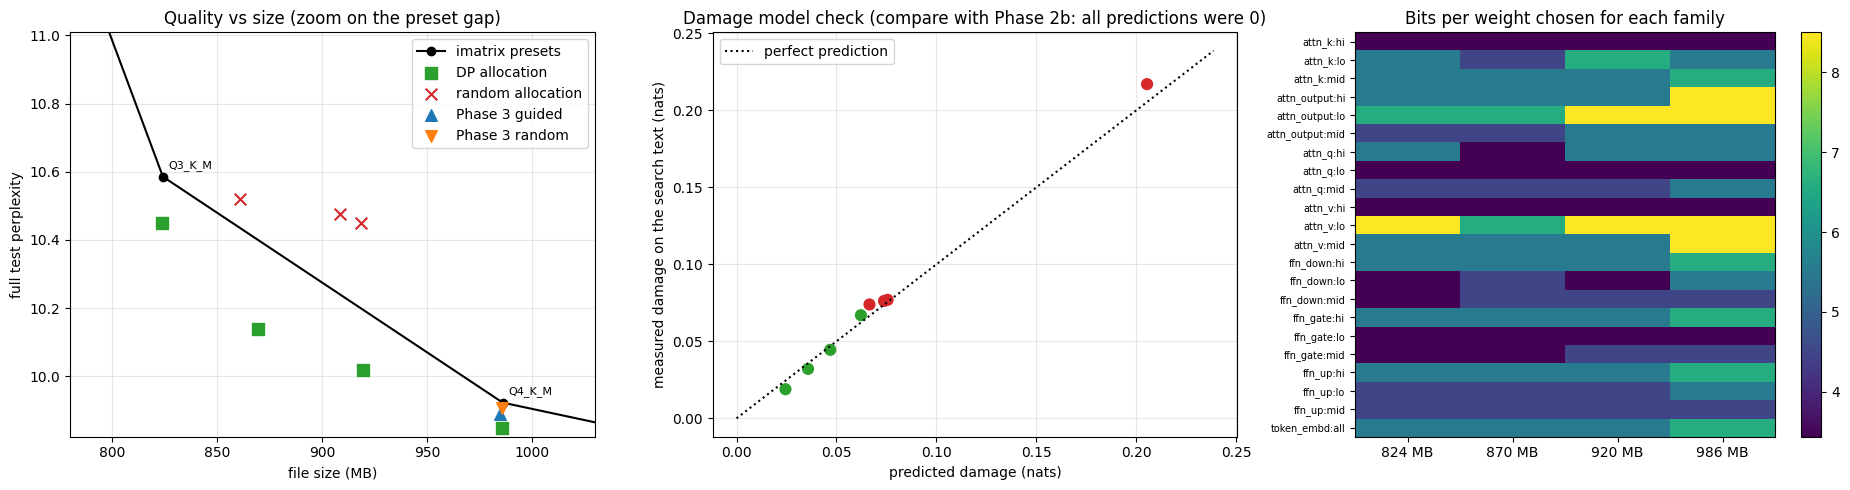

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
a = ax[0]
a.plot(pre.size_mb, pre.ppl_full, "ko-", label="imatrix presets", zorder=3)
for _, r in pre.iterrows():
    a.annotate(r["name"].replace("preset_imx_", ""), (r.size_mb, r.ppl_full), textcoords="offset points", xytext=(4, 6), fontsize=8)
for pref, col, mk, lb in [("dp_", "tab:green", "s", "DP allocation"), ("rnd_", "tab:red", "x", "random allocation"),
                           ("old_guided", "tab:blue", "^", "Phase 3 guided"), ("old_random", "tab:orange", "v", "Phase 3 random")]:
    d = res[res.name.str.startswith(pref)]
    if len(d):
        a.scatter(d.size_mb, d.ppl_full, c=col, marker=mk, s=70, label=lb, zorder=4)
gap = pre[(pre.size_mb >= 800) & (pre.size_mb <= 1000)]
a.set_xlim(780, 1030); a.set_ylim(gap.ppl_full.min() - 0.1, gap.ppl_full.max() * 1.04)
a.set_xlabel("file size (MB)"); a.set_ylabel("full test perplexity"); a.set_title("Quality vs size (zoom on the preset gap)")
a.legend(); a.grid(alpha=.3)

b = ax[1]
mine = res[res.name.str.match(r"^(dp_|rnd_)")].copy()
mine["pred"] = [records[n]["pred_dmg"] for n in mine.name]
mine["actual"] = [math.log(records[n]["ppl_search"] / ref_s) for n in mine.name]
b.scatter(mine.pred, mine.actual, c=["tab:green" if n.startswith("dp_") else "tab:red" for n in mine.name], s=60)
lim = max(mine.pred.max(), mine.actual.max()) * 1.1
b.plot([0, lim], [0, lim], "k:", label="perfect prediction")
b.set_xlabel("predicted damage (nats)"); b.set_ylabel("measured damage on the search text (nats)")
b.set_title("Damage model check (compare with Phase 2b: all predictions were 0)"); b.legend(); b.grid(alpha=.3)

c = ax[2]
im = c.imshow(bits.values, aspect="auto", cmap="viridis")
c.set_xticks(range(len(BUDGETS_MB))); c.set_xticklabels([f"{B} MB" for B in BUDGETS_MB])
c.set_yticks(range(len(FAMS))); c.set_yticklabels(FAMS, fontsize=7)
c.set_title("Bits per weight chosen for each family"); plt.colorbar(im, ax=c)
plt.tight_layout()
plt.savefig(RESULTS / f"phase2c_{MODEL_NAME}_summary.png", dpi=150)
plt.show()

## 12. Save results (and the models for the laptop), then clean up

In [22]:
res.to_csv(RESULTS / f"phase2c_{MODEL_NAME}_results.csv", index=False)
tab.to_csv(RESULTS / f"phase2c_{MODEL_NAME}_family_damage.csv", index=False)
allocs = {str(B): {f: LEVELS[l] for f, l in zip(FAMS, plans[B])} for B in BUDGETS_MB}
(RESULTS / f"phase2c_{MODEL_NAME}_allocations.json").write_text(json.dumps(allocs, indent=1))
meta = {"model": MODEL_ID, "llama_cpp_commit": LLAMA_COMMIT, "levels": LEVELS, "ratios": R, "scales": A,
        "budgets": BUDGETS_MB, "search_chunks": SEARCH_CHUNKS, "test_chunks": TEST_CHUNKS,
        "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
        "date": time.strftime("%Y-%m-%d %H:%M")}
(RESULTS / f"phase2c_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=1))

if SAVE_FINAL_GGUFS:
    outdir = RESULTS / "final_models"; outdir.mkdir(exist_ok=True)
    for q in ["Q3_K_M", "Q4_K_M"]:
        p = outdir / f"{MODEL_NAME}-{q}-imx.gguf"
        if not p.exists():
            quantize(p, q, [], imatrix=True)
    for B in SAVE_BUDGETS:
        p = outdir / f"{MODEL_NAME}-dp{B}.gguf"
        if not p.exists():
            quantize(p, HIGH, overrides_from_idx(expand(plans[B])), imatrix=True)
    print({p.name: f"{p.stat().st_size/1e6:.0f} MB" for p in sorted(outdir.glob('*.gguf'))})

dump(["dp_", "rnd_", "preset_imx_", "old_"])
if CLEANUP:
    shutil.rmtree(WORK / "hf", ignore_errors=True)
    shutil.rmtree(MODELS, ignore_errors=True)
    print(sh(f"du -sh {WORK}", check=False))

$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
{
 "model": "Qwen/Qwen2.5-1.5B",
 "llama_cpp_commit": "6b9ba4f2e",
 "levels": [
  "q3_k",
  "q4_k",
  "q5_k",
  "q6_k",
  "q8_0"
 ],
 "ratios": {
  "q3_k": 1.0,
  "q4_k": 0.28994234937381014,
  "q5_k": 0.07078254642010501,
  "q6_k": 0.03071753976308979,
  "q8_0": 0.0
 },
 "scales": {
  "attn_k:hi": 0.0,
  "attn_k:lo": 0.0004551954040619133,
  "attn_k:mid": 0.004518201175961634,
  "attn_output:hi": 0.002655922375781077,
  "attn_output:lo": 0.011193272543720758,
  "attn_output:mid": 0.011884149779688722,
  "attn_q:hi": 0.0005364513173481471,
  "attn_q:lo": 0.0,
  "attn_q:mid": 0.0047593422639337106,
  "attn_v:hi": 1.3309013664723498e-05,
  "attn_v:lo": 0.002789636826655072,
  "attn_v:mid": 0.006514915705261634,
  "ffn_down:hi": 0.01265114949085017,
  "ffn_down:lo": 0.002051503276595365,
  "ffn_down:mid": 0.020506311462141748,
  "ffn_gate:hi": 0.006460017442012177,
  "ffn_gate:lo": 0.0,
  "ffn_gate:mid": 0.012580714324047686,
  "ffn

## How to read the result
1. **Stage A:** if the replay reproduces the Phase 3 search perplexities (8.8646 / 8.8826 / 8.9310), the rebuilt configs are the same models. The full-test comparison then tells whether the Phase 3 guided gain (+0.27% on 100 chunks) holds on all of the test split.
2. **Model check (middle plot):** points near the diagonal mean the family-level damage model works. In Phase 2b every prediction was 0.
3. **Preset sizes (824 and 986 MB):** the DP allocation uses one level per family, so it cannot copy the preset's alternating q6_k pattern. Matching the preset there is already a good sign; being clearly worse means uniform-per-family allocation is too coarse.
4. **In-between sizes (870 and 920 MB):** here no preset exists. `vs_curve_pct` above zero means a better model than interpolating between presets, and the random allocations show how much of that is due to the solver. The preset curve is convex, so a straight line between presets would flatter the result; the monotone interpolation through four presets is the fairer reference but is still an estimate.
5. **If nothing beats the curve:** report it. The measured contributions remain: the embedding sensitivity, additivity at family level, the diagnosis of the Phase 2b failure, the Phase 3 overfitting analysis and the speed measurements.

**Laptop:** copy the `.gguf` files from `results/final_models/` and run `llama-bench` from `C:\llama-cuda` (`-ngl 99`) and `C:\llama-cpu` (`-ngl 0`, try `-t` values such as 6, 8 and 14) with `-r 5`. Record the llama.cpp release tag.